# Segment subject brain according to the MultiConn atlas

To use the MultiConn atlas, one must segment individual brains according to the parcellation used in [Alemán-Gómez et. al 2022](https://www.nature.com/articles/s41597-022-01624-8).

The MultiConn's parcellation is a combination of the cortical parcellation from [Cammoun et al. 2012]() and the subcortical parcellation from [Battistella et al. 2016](https://link.springer.com/article/10.1007/s00429-016-1336-4).

In this notebook, we first generate the cortical and subcortical parcellations, and then use the Parcellation class to combine both into the MultiConn's parcellation.

# Batch Wise Run
Run the code for all subjects of a given dataset.

## 📦 Imports

In [1]:
import mindmap as mm
from pathlib import Path

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- FREESURFER reconstruction folder.
    - T1
- Lausanne 2018 atlas
    - Left hemisphere annot file
    - Right hemisphere annot file
- Thalamic Nuclei atlas

📤 **<font color=pink>Outputs</font>**
- `parc`: MultiConn parcellation

🛠️ **<font color=violet>Configuration</font>**:
- `fconfig`: Configuration file.

🛠️ **<font color=violet>Lausanne 2018 parcellation</font>**:
- `margin`: white matter growing

🛠️ **<font color=violet>Thalamic Nuclei parcellation</font>**:
- `thresh`: Probability threshold to discretize atlas

In [2]:
############# Parameters #################
# configuration
fconfig = "../configurations/spike.yml"

# Lausanne 2018 parcellation
margin = 2

# Thalamic Nuclei parcellation
thresh = 0.05

# other options
overwrite = True 
##########################################


# configuration
config   = mm.io.read_config(fconfig)
subjects = config["SUBS"]
mm_dir   = Path(config["MM_DIR"])

# output file generic name
fname = lambda sub: (mm_dir/sub/"parc"/f"{sub}_multiConn4-dseg.nii.gz",  mm_dir/sub/"parc"/f"{sub}_multiConn4-dseg.txt")

## ♾️ Loop

In [3]:
for sub in subjects:
    nii_fname, clut_fname = fname(sub)

    # check existence of folder/file
    if nii_fname.exists():
        if not overwrite:
            print(f"Skipping subject {sub} because parcellation already exists.")
            continue
    else:
        if not nii_fname.parent.exists():
            nii_fname.parent.mkdir(parents=True)    
    
    # create multiconn parcellation
    print(f"Generating MultiConn parcellation for subject {sub}...")
    try:
        multi_conn = mm.utils.parcelate(sub, "multiconn", margin=margin, threshold=thresh, verbose=0)
    except Exception as e:
        print(f"\033[91mMultiConn parcellation failed for subject {sub}\033[0m")
        print(f"Reason: {e}")
        continue

    # save
    multi_conn.save(nii_fname, clut_fname)
    print(f"\033[92mSuccessfully generated MultiConn Parcellation for subject {sub}\033[0m")

Generating MultiConn parcellation for subject sub-pat01...
DATA SUMMARY
Dataset: spike
Subject: sub-pat01
Retrieved objects:
- T1
Missing objects:
Successfully generated MultiConn Parcellation for subject sub-pat01
Generating MultiConn parcellation for subject sub-pat02...
DATA SUMMARY
Dataset: spike
Subject: sub-pat02
Retrieved objects:
- T1
Missing objects:
Successfully generated MultiConn Parcellation for subject sub-pat02
Generating MultiConn parcellation for subject sub-pat03...
DATA SUMMARY
Dataset: spike
Subject: sub-pat03
Retrieved objects:
- T1
Missing objects:
Successfully generated MultiConn Parcellation for subject sub-pat03
Generating MultiConn parcellation for subject sub-pat04...
DATA SUMMARY
Dataset: spike
Subject: sub-pat04
Retrieved objects:
- T1
Missing objects:
Successfully generated MultiConn Parcellation for subject sub-pat04
Generating MultiConn parcellation for subject sub-pat05...
DATA SUMMARY
Dataset: spike
Subject: sub-pat05
Retrieved objects:
- T1
Missing ob

# Step Wise Run

Run the code step by step for a single subject.

## 📦 Imports

In [1]:
from pathlib import Path
import subprocess
import os

import mindmap as mm
from mindmap.utils.mri import Parcellation

import pandas as pd

import nibabel as nib
import ants

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- FREESURFER reconstruction folder.
    - T1
- Lausanne 2018 atlas
    - Left hemisphere annot file
    - Right hemisphere annot file
- Thalamic Nuclei atlas

In [3]:
env = mm.io.read_config("../configurations/spike.yml")
sub = env["SUBS"][0]

# set freesurfer configuration
os.environ["SUBJECTS_DIR"]    = env["FS_DIR"]
os.environ["FREESURFER_HOME"] = env["FS_HOME"]

# directories
fs_dir  = Path(env["FS_DIR"])
fs_home = Path(env["FS_HOME"])
mm_dir  = Path(env["MM_DIR"])

# data
data = mm.io.read_dataset(sub, "T1", mri_dtype="ants")
std  = mm.io.read_standards("mni", "ctx", "thal", "thal_clut")

DATA SUMMARY
Dataset: spike
Subject: sub-pat01
Retrieved objects:
- T1
Missing objects:


## Segment according to the Lausanne 2018 parcellation

#### ⚙️ <font color=green>**Segmentation using FreeSurfer**</font> (1 min 30 s)

📤 **<font color=pink>Outputs</font>**
- `laus2018`: Lausanne 2018 parcellation

🛠️ **<font color=violet>Lausanne 2018 parcellation</font>**:
- `margin`: white matter growing

In [4]:
################ Parameters ##################
margin = 2
##############################################



print(f"\033[96mSegmenting subject {sub} according to the Lausanne 2018 atlas ...\033[0m")

# temporary files
annotL    = fs_dir/sub/"label"/"lh.my-atlas.annot" 
annotR    = fs_dir/sub/"label"/"rh.my-atlas.annot" 
dparc_fs  = fs_dir/sub/"mri"/"my-atlas_space-fs_dparc.nii.gz"
dparc_sub = fs_dir/sub/"mri"/"my-atlas_space-orig_dparc.nii.gz"

print(f"\033[96mRegistering surface-based segmentation ...\033[0m")
subprocess.run(
    [
        "mri_surf2surf",
        "--srcsubject", "fsaverage",
        "--trgsubject", sub,
        "--hemi", "lh",
        "--sval-annot", std["ctx"]["LAUSL"],
        "--tval", str(annotL),
    ],
    stdout=subprocess.PIPE,
    universal_newlines=True,
)

subprocess.run(
    [
        "mri_surf2surf",
        "--srcsubject", "fsaverage",
        "--trgsubject", sub,
        "--hemi", "rh",
        "--sval-annot", std["ctx"]["LAUSR"],
        "--tval", str(annotR),
    ],
    stdout=subprocess.PIPE,
    universal_newlines=True,
)

print(f"\033[96mExpanding surface-based segmentation to volumetric segmentation ...\033[0m")
subprocess.run(
    [
        "mri_aparc2aseg",
        "--s", sub,
        "--annot", "my-atlas",
        "--wmparc-dmax", str(margin),
        "--labelwm",
        "--hypo-as-wm",
        "--new-ribbon",
        "--o", str(dparc_fs),
    ],
    stdout=subprocess.PIPE,
    universal_newlines=True,
)

print(f"\033[96mRegistering to subject ...\033[0m")
subprocess.run(
    [
        "mri_vol2vol",
        "--mov", str(dparc_fs),
        "--targ", str(fs_dir/sub/"mri"/"rawavg.mgz"),
        "--regheader",
        "--o", str(dparc_sub),
        "--no-save-reg",
        "--interp", "nearest",
    ],
    stdout=subprocess.PIPE, 
    universal_newlines=True,
)

Segmenting subject sub-pat01 according to the Lausanne 2018 atlas ...
Registering surface-based segmentation ...
Expanding surface-based segmentation to volumetric segmentation ...
Registering to subject ...


CompletedProcess(args=['mri_vol2vol', '--mov', '/media/nino/DATA/SPIKE/derivatives/freesurfer-7.4.1/sub-pat01/mri/my-atlas_space-fs_dparc.nii.gz', '--targ', '/media/nino/DATA/SPIKE/derivatives/freesurfer-7.4.1/sub-pat01/mri/rawavg.mgz', '--regheader', '--o', '/media/nino/DATA/SPIKE/derivatives/freesurfer-7.4.1/sub-pat01/mri/my-atlas_space-orig_dparc.nii.gz', '--no-save-reg', '--interp', 'nearest'], returncode=0, stdout='movvol /media/nino/DATA/SPIKE/derivatives/freesurfer-7.4.1/sub-pat01/mri/my-atlas_space-fs_dparc.nii.gz\ntargvol /media/nino/DATA/SPIKE/derivatives/freesurfer-7.4.1/sub-pat01/mri/rawavg.mgz\noutvol /media/nino/DATA/SPIKE/derivatives/freesurfer-7.4.1/sub-pat01/mri/my-atlas_space-orig_dparc.nii.gz\ninvert 0\ntal    0\ntalres 2\nregheader 1\nnoresample 0\ninterp  nearest (0)\nprecision  float (3)\nGdiag_no  -1\nSynth      0\nSynthSeed  1744525831\n\nComputing registration based on scanner-to-scanner\n\nFinal tkRAS-to-tkRAS Matrix is:\n-1.00000   0.00000   0.00000   0.00000

#### ⚙️ <font color=green>**Create the Color Look-Up Table**</font>

The Lausanne 2018 atlas includes more cortical regions than those in the FreeSurfer color look-up table (LUT). To create an updated color LUT for our segmentation, we will do the following:

- **Retain Non-Cortical Regions**: Keep the non-cortical regions from the FreeSurfer color LUT.
- **Add New Cortical Regions**: Incorporate the new cortical regions from the Lausanne atlas, ensuring we follow the FreeSurfer indexing system.

**Indexing in FreeSurfer**: The FreeSurfer color LUT assigns indices as follows:
- **1000-1999**: Right cortical gray matter regions
- **2000-2999**: Left cortical gray matter regions
- **3000-3999**: Right cortical white matter regions
- **4000-4999**: Left cortical white matter regions

In contrast, the cortical regions in the annotation files are indexed from 1 to the total number of regions. <br>

**Maintaining Proper Indexing**: To ensure correct indexing in our color LUT, we will:
- Create separate entries for right and left gray and white matter.
- Add 1000 for right gray, 2000 for left gray, 3000 for right white, and 4000 for left white, respectively.

This structured approach will ensure that our color LUT accurately represents the cortical regions in the Lausanne atlas while maintaining compatibility with FreeSurfer's indexing system.



In [5]:
# load data
#volume  = nib.load(dparc_sub)                                    # Volume CHOOSE WHICH VOLUME
volume  = nib.load(dparc_fs)
fs_clut = mm.io.read_clut(fs_home/"FreeSurferColorLUT.txt")     # FreeSurfer color LUT 
lh_clut = mm.io.read_clut(annotL)                               # Left annotation color LUT
rh_clut = mm.io.read_clut(annotR)                               # Right annotation color LUT 

# correct clut 
laus2018_clut = fs_clut[(fs_clut["#No."]<1000) | (fs_clut["#No."]>4999)]     # Keep non-cortical regions 

gm_lh_clut, wm_lh_clut = lh_clut.copy(), lh_clut.copy()
gm_rh_clut, wm_rh_clut = rh_clut.copy(), rh_clut.copy()

gm_lh_clut["#No."] += 1000          # 1000-1999 
gm_rh_clut["#No."] += 2000          # 2000-2999
wm_lh_clut["#No."] += 3000          # 3000-3999
wm_rh_clut["#No."] += 4000          # 4000-4999

laus2018_clut = pd.concat([laus2018_clut, gm_lh_clut, gm_rh_clut, wm_lh_clut, wm_lh_clut])
laus2018_clut = laus2018_clut.sort_values(by=["#No."])

#### ⚙️ <font color=green>**Create a parcellation object and fuse gray+white matter**</font>
We change the labels so that white matter regions are assigned to the corresponding gray matter regions with the same name. At this point, we do not need to distinguish between the two.

In [6]:
laus2018 = Parcellation(volume, laus2018_clut)
laus2018.change_ids([(3001, 3999), (4001, 4999)], lambda x: x-2000)

🗑️ **Deleting temporary files**

In [7]:
annotL.unlink()
annotR.unlink()
dparc_fs.unlink()
dparc_sub.unlink()

🌟 **Visualization of the Lausanne 2018 parcellation**

In [8]:
image_laus = laus2018.get_image()

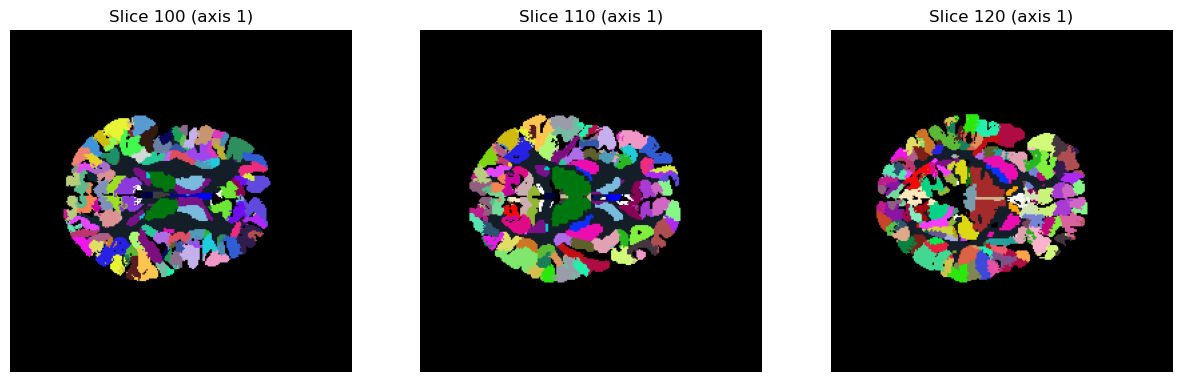

In [9]:
slices = [100, 110, 120]
mm.viz.show_slices(image_laus, slices, axis=1)

## Segmenting according to the Thalamic Nuclei atlas

#### ⚙️ <font color=green>**Segment using ANTs registration**</font>

📤 **<font color=pink>Outputs</font>**
- `thal`: Thalamic nuclei parcellation

🛠️ **<font color=violet>Thalamic Nuclei parcellation</font>**:
- `thresh`: Probability threshold to discretize atlas

In [10]:
########### Parameters ###########
thresh = 0.05 
##################################


# registration transform
mytx = ants.registration(
    fixed = std["mni"],
    moving = data["T1"],
    type_of_transform = "SyN",
)

# registration 
volume = ants.apply_transforms(
    fixed = data["T1"],
    moving = std["thal"],
    transformlist = mytx["invtransforms"],
    imagetype = 3,
    interpolator = "linear",
)

# create parcellation object and discretize it
volume = mm.utils.ants_to_nibabel(volume)
thal   = Parcellation(volume, std["thal_clut"])
thal   = thal.prob2dseg(thresh=thresh)

#### <font color=yellow>🌟</font> Visualization of the thalamic nuclei parcellation

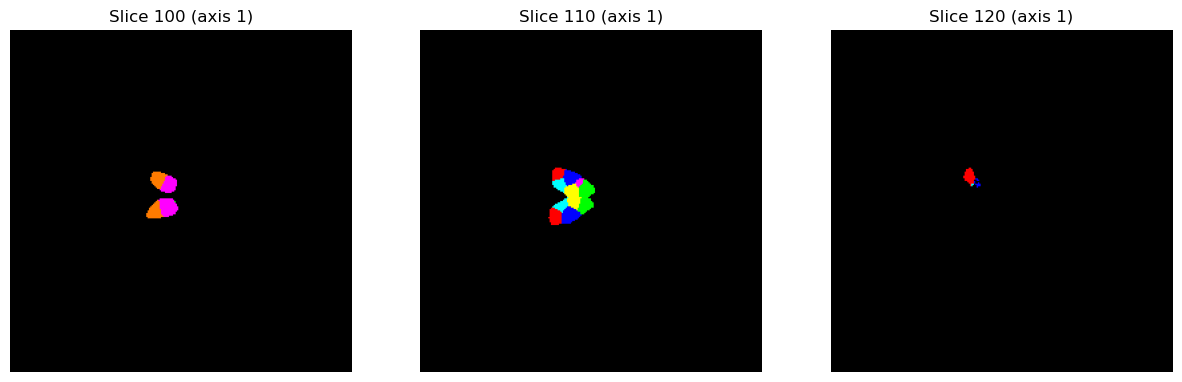

In [11]:
image_thal = thal.get_image()
mm.viz.show_slices(image_thal, slices, axis=1)

## Fuse the Lausanne 2018 and Thalamic Parcellations
#### ⚙️ <font color=green>**Use Chimera inspired protocol**</font>

In [12]:
# Extract and rename parts of interest from the Lausanne 2018 parcellation.
ctx_lh = laus2018.retain([(1001, 1999), (3001, 3999)])
ctx_lh.change_labels(prefix="ctx-lh-")

ctx_rh = laus2018.retain([(2001, 2999), (4001, 4999)])
ctx_rh.change_labels(prefix="ctx-rh-")

subc_lh = laus2018.retain([11, 12, 13, 26, 18, 17])
subc_lh.change_labels(replace={"Left-":"", "Accumbens-area":"accumbens_area"}, prefix="subc-lh-", lower=True)

subc_rh = laus2018.retain([50, 51, 52, 58, 54, 53])
subc_rh.change_labels(replace={"Right-":"", "Accumbens-area":"accumbens_area"}, prefix="subc-rh-", lower=True)

# Extract and rename parts of interest from the thalamic parcellation.
thal_lh = thal.retain([(8, 14)])

thal_rh = thal.retain([(1,7)])

brain_stem = laus2018.retain([16])
brain_stem.change_labels(replace={"-":"_"})

# join parts of interest
multi_conn = mm.utils.Parcellation()
multi_conn = multi_conn.join(ctx_rh)
multi_conn = multi_conn.join(thal_rh)
multi_conn = multi_conn.join(subc_rh)
multi_conn = multi_conn.join(ctx_lh)
multi_conn = multi_conn.join(thal_lh)
multi_conn = multi_conn.join(subc_lh)
multi_conn = multi_conn.join(brain_stem)

#### <font color=yellow>🌟</font> Visualize the MultiConn Parcellation

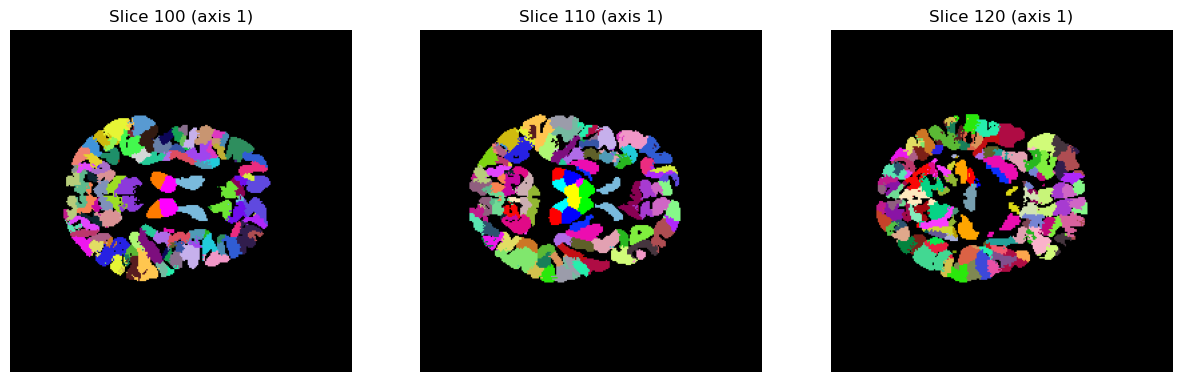

In [13]:
image_multiconn = multi_conn.get_image()
mm.viz.show_slices(image_multiconn, slices, axis=1)

## 💾 Saving parcellation

In [14]:
folder = mm_dir/sub/"parc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving MultiConn parcellation for subject: {sub}")
multi_conn.save(
    folder/f"{sub}_multiConn4-dseg.nii.gz",     # rename the scale if needed
    folder/f"{sub}_multiConn4-dseg.txt",
)

Saving MultiConn parcellation for subject: sub-pat01
